# Do starting pitchers fatigue sooner in the heat?

**Question:** within a start, a pitcher's fastball velocity eventually drops. Does that **fatigue point** come earlier (at a lower pitch count) in hot weather?

**Plan**
1. Load Statcast seasons (from local files, or downloaded with pybaseball if missing) and find every **starting pitcher's start**.
2. Define a **fatigue point** per start: the pitch count at which his fastball velocity first falls a set amount below his early-game level.
3. Get **game-time temperature** for every game from the MLB Stats API.
4. Analyze:
   - how velocity level and the velocity decline curve change with temperature,
   - **survival analysis**: the share of starts not yet fatigued at each pitch count, by temperature,
   - a **Cox model stratified by pitcher**, so each pitcher is only compared with himself.

**Why survival analysis?** Many starts end before the pitcher fatigues, because the manager pulls him. Those starts aren't "never fatigued"; we only know he hadn't fatigued *by* his last pitch. Survival analysis handles this kind of cut-off data (called *censoring*) correctly. Dropping those starts or treating them as fatigue would bias the result.

In [2]:
# Install once, in VS Code's terminal, using the SAME Python your notebook kernel uses:
#   python -m pip install pybaseball pyarrow statsmodels requests matplotlib pandas ipykernel
# (or run  %pip install ...  in a notebook cell, which always targets the active kernel)

import json, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

try:                                  # display() exists in notebooks; plain scripts fall back to print
    from IPython.display import display
except ImportError:
    display = print

# ---- Where your data lives ------------------------------------------------------------
PROJECT_DIR = Path.home() / "baseball" / "arsenal_transformer"
# To reuse the parquet files you saved to Google Drive (no 20-minute re-download), either:
#   1) download raw_2025.parquet and raw_2026.parquet from Drive into PROJECT_DIR / "data", or
#   2) with Google Drive for desktop installed, point PROJECT_DIR at the synced folder:
#      macOS:   Path.home() / "Library/CloudStorage/GoogleDrive-YOUR_EMAIL/My Drive/arsenal_transformer"
#      Windows: Path("G:/My Drive/arsenal_transformer")
# ---------------------------------------------------------------------------------------
DATA_DIR = PROJECT_DIR / "data";   DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_DIR / "fatigue"; OUT_DIR.mkdir(parents=True, exist_ok=True)
SEASONS = [2025, 2026]

# Fatigue definition (try other values to check the result is robust)
BASE_LO, BASE_HI = 10, 40   # pitch-count window for his early-game baseline velocity
WINDOW = 8                  # rolling average over this many fastballs
DROP = 1.0                  # mph below baseline that counts as "fatigued"
MIN_PITCHES = 50            # only starts at least this long

print("Data folder:", DATA_DIR.resolve())
for y in SEASONS:
    f = DATA_DIR / f"raw_{y}.parquet"
    print(f"  raw_{y}.parquet:", "found" if f.exists() else "missing -> will download (~10-20 min)")

Data folder: /Users/jinzhixu/baseball/arsenal_transformer/data
  raw_2025.parquet: missing -> will download (~10-20 min)
  raw_2026.parquet: missing -> will download (~10-20 min)


## 1. Load Statcast and find starts

`pitch_count` = how many pitches the pitcher has thrown so far in that game. The two **starters** in a game are the first two pitchers to appear (one per team). Openers and bulk relievers are mostly removed by requiring at least `MIN_PITCHES` pitches.

In [3]:
cols = ["pitcher", "game_pk", "game_date", "game_type", "at_bat_number",
        "pitch_number", "pitch_type", "release_speed"]

def load_season(year):
    path = DATA_DIR / f"raw_{year}.parquet"
    if not path.exists():
        from pybaseball import cache, statcast
        cache.enable()
        print(f"{year}: downloading with pybaseball (keep VS Code open)...")
        statcast(start_dt=f"{year}-03-15", end_dt=f"{year}-10-05").to_parquet(path, index=False)
    df_ = pd.read_parquet(path, columns=cols)
    print(f"{year}: {len(df_):,} pitches")
    return df_

sc = pd.concat([load_season(y) for y in SEASONS], ignore_index=True)
sc = sc[sc["game_type"] == "R"].copy()
sc["pitch_type"] = sc["pitch_type"].astype("category")   # saves memory
sc["game_date"] = pd.to_datetime(sc["game_date"])
print(f"Statcast data in memory: {sc.memory_usage(deep=True).sum() / 1e9:.2f} GB")

sc = sc.sort_values(["game_pk", "at_bat_number", "pitch_number"]).reset_index(drop=True)
sc["pitch_count"] = sc.groupby(["game_pk", "pitcher"]).cumcount() + 1

# Starters = first pitcher to appear for each team (the first two pitchers in the game)
first_ab = sc.groupby(["game_pk", "pitcher"])["at_bat_number"].min().reset_index()
first_ab["order"] = first_ab.groupby("game_pk")["at_bat_number"].rank(method="first")
starters = first_ab.loc[first_ab["order"] <= 2, ["game_pk", "pitcher"]]

st = sc.merge(starters, on=["game_pk", "pitcher"])
total = st.groupby(["game_pk", "pitcher"])["pitch_count"].transform("max")
st = st[total >= MIN_PITCHES]
print(f"{len(sc):,} pitches | {st.groupby(['game_pk', 'pitcher']).ngroups:,} starts "
      f"with ≥{MIN_PITCHES} pitches")

2025: downloading with pybaseball (keep VS Code open)...
This is a large query, it may take a moment to complete


  0%|          | 1/205 [00:01<05:54,  1.74s/it]/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  1%|          | 2/205 [00:03<06:27,  1.91s/it]/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use

2025: 761,524 pitches
2026: downloading with pybaseball (keep VS Code open)...
This is a large query, it may take a moment to complete


  0%|          | 0/205 [00:00<?, ?it/s]/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  0%|          | 1/205 [00:00<00:54,  3.73it/s]/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  1%|          | 2/205 [00:00<01:03,  3.21it/s]/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated 

2026: 759,679 pitches
Statcast data in memory: 0.17 GB
1,429,320 pitches | 9,140 starts with ≥50 pitches


In [8]:
st.head()

,pitcher,game_pk,game_date,game_type,at_bat_number,pitch_number,pitch_type,release_speed,pitch_count
0,691951,776135,2025-09-28,R,1,1,FF,91.3,1
1,691951,776135,2025-09-28,R,1,2,FF,93.1,2
2,691951,776135,2025-09-28,R,1,3,FF,91.8,3
3,691951,776135,2025-09-28,R,1,4,FF,92.5,4
4,691951,776135,2025-09-28,R,1,5,FF,92.7,5


In [7]:
sc.shape

(1429320, 9)

## 2. Fatigue point per start

For each start, use his **primary fastball** in that game (whichever of four-seamer or sinker he threw most):
- **Baseline** = median velocity of fastballs thrown between pitch `BASE_LO` and `BASE_HI` (skips the first few warm-up pitches).
- **Fatigue point** = the first pitch count after `BASE_HI` where the average of his last `WINDOW` fastballs is at least `DROP` mph below baseline.
- If that never happens, the start is **censored** at its final pitch count.

In [9]:
def fatigue_point(g):
    total_pc = g["pitch_count"].max()
    fb_counts = g.loc[g["pitch_type"].isin(["FF", "SI"]), "pitch_type"].value_counts()
    if fb_counts.empty or fb_counts.iloc[0] < 15:
        return None
    fb = g[(g["pitch_type"] == fb_counts.index[0]) & g["release_speed"].notna()]
    early = fb.loc[fb["pitch_count"].between(BASE_LO, BASE_HI), "release_speed"]
    if len(early) < 6:
        return None
    base = early.median()
    roll = fb["release_speed"].rolling(WINDOW).mean()
    hit = fb[(fb["pitch_count"] > BASE_HI) & (roll <= base - DROP)]
    fatigued = not hit.empty
    return pd.Series({
        "fb_type": fb_counts.index[0], "baseline_velo": base, "total_pitches": total_pc,
        "time": hit["pitch_count"].iloc[0] if fatigued else total_pc,   # pitch count
        "event": int(fatigued),                                        # 1 = fatigued, 0 = censored
    })

starts = (st.groupby(["game_pk", "pitcher", "game_date"])
            .apply(fatigue_point, include_groups=False).dropna().reset_index())
starts["event"] = starts["event"].astype(int)
print(f"{len(starts):,} starts analysed | {starts['event'].mean():.0%} reached the fatigue point")
display(starts.head())

8,476 starts analysed | 37% reached the fatigue point


,game_pk,pitcher,game_date,fb_type,baseline_velo,total_pitches,time,event
0,776135,621121,2025-09-28,SI,91.75,54.0,54.0,0
1,776135,691951,2025-09-28,FF,92.60,96.0,68.0,1
2,776136,676664,2025-09-28,FF,92.20,113.0,113.0,0
3,776137,657277,2025-09-28,SI,93.70,78.0,78.0,0
4,776137,685326,2025-09-28,FF,94.75,62.0,62.0,0


## 3. Game-time temperature

The MLB Stats API schedule can include each game's weather (temperature at first pitch, conditions, wind). It's fetched one month at a time and cached to your project folder. Games still missing weather are fetched one by one from the game feed.

**Domes and closed roofs:** their condition reads "Dome" or "Roof Closed", and the temperature is the controlled indoor value. They're kept separately as an indoor comparison group.

In [17]:
OUT_DIR

PosixPath('/Users/jinzhixu/baseball/arsenal_transformer/fatigue')

In [10]:
WEATHER_FILE = OUT_DIR / "game_weather.parquet"
API = "https://statsapi.mlb.com/api"

def schedule_weather(year):
    rows = []
    for month in range(3, 11):
        start = f"{year}-{month:02d}-01"
        end = (pd.Timestamp(start) + pd.offsets.MonthEnd(0)).strftime("%Y-%m-%d")
        r = requests.get(f"{API}/v1/schedule", timeout=30, params={
            "sportId": 1, "gameType": "R", "startDate": start, "endDate": end,
            "hydrate": "weather"})
        r.raise_for_status()
        for d in r.json().get("dates", []):
            for g in d.get("games", []):
                w = g.get("weather") or {}
                rows.append({"game_pk": g["gamePk"], "day_night": g.get("dayNight"),
                             "venue": (g.get("venue") or {}).get("name"),
                             "temp": w.get("temp"), "condition": w.get("condition"),
                             "wind": w.get("wind")})
        time.sleep(0.2)
    return pd.DataFrame(rows)

def feed_weather(pk):
    r = requests.get(f"{API}/v1.1/game/{pk}/feed/live", timeout=30)
    r.raise_for_status()
    gd = r.json().get("gameData", {})
    w = gd.get("weather") or {}
    return {"temp": w.get("temp"), "condition": w.get("condition"), "wind": w.get("wind"),
            "venue": (gd.get("venue") or {}).get("name")}

if WEATHER_FILE.exists():
    weather = pd.read_parquet(WEATHER_FILE)
    print("Loaded cached weather")
else:
    weather = pd.concat([schedule_weather(y) for y in SEASONS], ignore_index=True)
    weather = weather.drop_duplicates("game_pk", keep="last")

needed = set(starts["game_pk"])
missing = [pk for pk in needed if pk not in set(weather.loc[weather["temp"].notna(), "game_pk"])]
print(f"{len(missing)} games still missing weather; fetching from game feeds...")
extra = []
for i, pk in enumerate(missing):
    try:
        extra.append({"game_pk": pk, **feed_weather(pk)})
    except Exception as e:
        print("  failed", pk, e)
    if i % 100 == 99:
        print(f"  {i + 1}/{len(missing)}")
    time.sleep(0.1)
if extra:
    weather = (pd.concat([weather, pd.DataFrame(extra)], ignore_index=True)
                 .sort_values("temp", na_position="first").drop_duplicates("game_pk", keep="last"))
weather.to_parquet(WEATHER_FILE, index=False)

weather["temp_f"] = pd.to_numeric(weather["temp"], errors="coerce")
cond = weather["condition"].fillna("").str.lower()
weather["indoor"] = cond.str.contains("dome") | cond.str.contains("roof closed")
display(weather["condition"].value_counts().head(12).to_frame())

0 games still missing weather; fetching from game feeds...


,count
condition,
Partly Cloudy,1705
Clear,905
Roof Closed,746
Cloudy,639
Sunny,499
Overcast,235
Dome,86
Rain,22
Drizzle,21


In [21]:
df = starts.merge(weather[["game_pk", "temp_f", "indoor", "condition", "day_night", "venue"]],
                  on="game_pk", how="left")
df = df.dropna(subset=["temp_f"])
df["month"] = df["game_date"].dt.month
df["season"] = df["game_date"].dt.year

# Days since this pitcher's previous start
df = df.sort_values(["pitcher", "game_date"])

df.shape #(8476, 15)

(8476, 15)

In [22]:
df.head()

,game_pk,pitcher,game_date,fb_type,baseline_velo,total_pitches,time,event,temp_f,indoor,condition,day_night,venue,month,season
4280,778540,434378,2025-03-29,FF,94.40,83.0,83.0,0,76.0,False,Partly Cloudy,day,Great American Ball Park,3,2025
4111,778444,434378,2025-04-04,FF,94.25,65.0,65.0,0,62.0,False,Sunny,day,Oracle Park,4,2025
3986,778376,434378,2025-04-09,FF,95.00,90.0,90.0,0,65.0,False,Sunny,day,Oracle Park,4,2025
3870,778313,434378,2025-04-15,FF,93.50,104.0,104.0,0,56.0,False,Partly Cloudy,night,Citizens Bank Park,4,2025
3722,778232,434378,2025-04-20,FF,94.30,98.0,98.0,0,75.0,False,Sunny,day,Angel Stadium,4,2025


In [23]:
df.describe()

,game_pk,pitcher,game_date,baseline_velo,total_pitches,time,event,temp_f,month,season
count,8476.0,8476.0,8476,8476.000000,8476.000000,8476.000000,8476.000000,8476.000000,8476.000000,8476.000000
mean,800122.63261,655152.225342,2025-12-22 07:26:48.872109568,94.292809,87.930864,79.663167,0.368216,73.727820,6.356300,2025.489264
min,776135.0,434378.0,2025-03-18 00:00:00,85.200000,50.000000,41.000000,0.000000,33.000000,3.000000,2025.000000
25%,777314.0,622663.0,2025-06-25 00:00:00,92.800000,82.000000,69.000000,0.000000,68.000000,5.000000,2025.000000
50%,778514.5,668964.0,2025-09-25 00:00:00,94.300000,90.000000,82.000000,0.000000,74.000000,6.000000,2025.000000
75%,823865.25,682847.0,2026-06-23 00:00:00,95.800000,96.000000,92.000000,1.000000,81.000000,8.000000,2026.000000
max,825108.0,837227.0,2026-09-27 00:00:00,103.200000,126.000000,126.000000,1.000000,103.000000,9.000000,2026.000000
std,23280.290402,56612.574917,NaN,2.268099,11.150827,15.730921,0.482349,10.348289,1.774549,0.499914


8,476 starts with temperature: 7,020 outdoors, 1,456 indoors


,starts,fatigued,median_total_pitches,mean_baseline_velo
temp_bin,,,,
<60°F,727,0.40,90.0,93.77
60–69°F,1370,0.38,90.0,94.21
70–79°F,2543,0.38,90.0,94.37
80°F+,2380,0.36,89.0,94.33


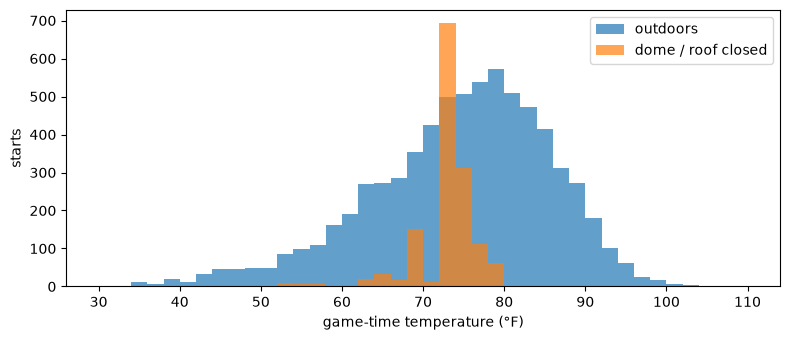

In [11]:
df = starts.merge(weather[["game_pk", "temp_f", "indoor", "condition", "day_night", "venue"]],
                  on="game_pk", how="left")
df = df.dropna(subset=["temp_f"])
df["month"] = df["game_date"].dt.month
df["season"] = df["game_date"].dt.year

# Days since this pitcher's previous start
df = df.sort_values(["pitcher", "game_date"])
df["rest_days"] = df.groupby("pitcher")["game_date"].diff().dt.days
df["rest"] = pd.cut(df["rest_days"], [0, 4, 5, 6, 400], labels=["≤4", "5", "6", "7+"])

BINS, LABELS = [-50, 60, 70, 80, 150], ["<60°F", "60–69°F", "70–79°F", "80°F+"]
df["temp_bin"] = pd.cut(df["temp_f"], BINS, labels=LABELS, right=False)
out = df[~df["indoor"]].copy()
print(f"{len(df):,} starts with temperature: {len(out):,} outdoors, {df['indoor'].sum():,} indoors")
display(out.groupby("temp_bin", observed=True).agg(
    starts=("event", "size"), fatigued=("event", "mean"),
    median_total_pitches=("total_pitches", "median"), mean_baseline_velo=("baseline_velo", "mean")).round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(out["temp_f"], bins=range(30, 111, 2), alpha=0.7, label="outdoors")
ax.hist(df.loc[df["indoor"], "temp_f"], bins=range(30, 111, 2), alpha=0.7, label="dome / roof closed")
ax.set_xlabel("game-time temperature (°F)"); ax.set_ylabel("starts"); ax.legend()
plt.tight_layout(); plt.show()

In [20]:
df.shape
#a full season is about 2,462–2,483 games

(8476, 15)

In [24]:
temp = out.groupby("temp_bin", observed=True).agg(
    starts=("event", "size"), fatigued=("event", "mean"),
    median_total_pitches=("total_pitches", "median"), mean_baseline_velo=("baseline_velo", "mean")).round(2)

temp.head()

,starts,fatigued,median_total_pitches,mean_baseline_velo
temp_bin,,,,
<60°F,727,0.40,90.0,93.77
60–69°F,1370,0.38,90.0,94.21
70–79°F,2543,0.38,90.0,94.37
80°F+,2380,0.36,89.0,94.33


## 4a. Does temperature change velocity *level*?

Compared within each pitcher: his baseline velocity in a start minus his average baseline that season. This separates "hot days make everyone throw harder (or softer)" from the fatigue question.

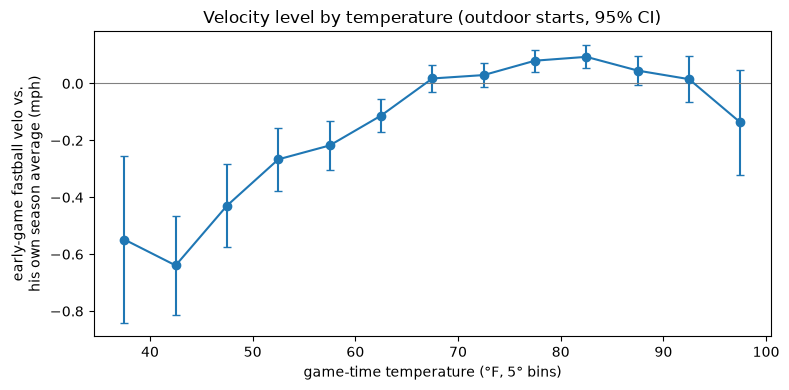

In [12]:
out["velo_vs_own_avg"] = out["baseline_velo"] - out.groupby(["pitcher", "season"])["baseline_velo"].transform("mean")

b = out.assign(t5=(out["temp_f"] // 5) * 5).groupby("t5")["velo_vs_own_avg"].agg(["mean", "sem", "size"])

b = b[b["size"] >= 30]

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(b.index + 2.5, b["mean"], yerr=1.96 * b["sem"], fmt="o-", capsize=3)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("game-time temperature (°F, 5° bins)")
ax.set_ylabel("early-game fastball velo vs.\nhis own season average (mph)")
ax.set_title("Velocity level by temperature (outdoor starts, 95% CI)")
plt.tight_layout(); plt.show()

## 4b. Average velocity decline through a start

Each fastball's velocity minus that start's baseline, averaged in 10-pitch bins, by temperature group.

**Read with care:** at high pitch counts only the pitchers still in the game are left, and those are usually the ones who *weren't* tiring. This plot shows the shape; the survival analysis below handles the selection properly.

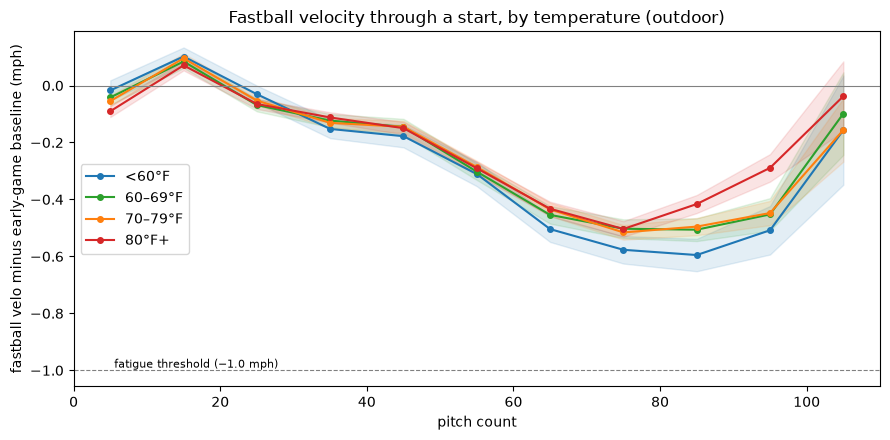

In [13]:
fb = st.merge(df.loc[~df["indoor"], ["game_pk", "pitcher", "fb_type", "baseline_velo", "temp_bin"]],
              on=["game_pk", "pitcher"])
fb = fb[fb["pitch_type"] == fb["fb_type"]]
fb["drop"] = fb["release_speed"] - fb["baseline_velo"]
fb["pc_bin"] = (fb["pitch_count"] // 10) * 10 + 5

curve = fb.groupby(["temp_bin", "pc_bin"], observed=True)["drop"].agg(["mean", "sem", "size"]).reset_index()
curve = curve[curve["size"] >= 50]
fig, ax = plt.subplots(figsize=(9, 4.5))
for (lab, g), c in zip(curve.groupby("temp_bin", observed=True), ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    ax.plot(g["pc_bin"], g["mean"], "o-", color=c, label=lab, ms=4)
    ax.fill_between(g["pc_bin"], g["mean"] - 1.96 * g["sem"], g["mean"] + 1.96 * g["sem"], color=c, alpha=0.12)
ax.axhline(0, color="gray", lw=0.8); ax.axhline(-DROP, color="gray", ls="--", lw=0.8)
ax.text(5, -DROP, f" fatigue threshold (−{DROP} mph)", va="bottom", fontsize=8)
ax.set_xlabel("pitch count"); ax.set_ylabel("fastball velo minus early-game baseline (mph)")
ax.set_title("Fastball velocity through a start, by temperature (outdoor)")
ax.legend(); plt.tight_layout(); plt.show()

temperature affects how hard pitchers throw, but this table shows little sign that it changes whether they fatigue.

## 4c. Survival curves: share of starts not yet fatigued

Kaplan–Meier estimate: at each pitch count, the share of starts that haven't hit the fatigue point yet, correctly accounting for pitchers removed before fatiguing. If heat speeds up fatigue, the hot curve drops earlier.

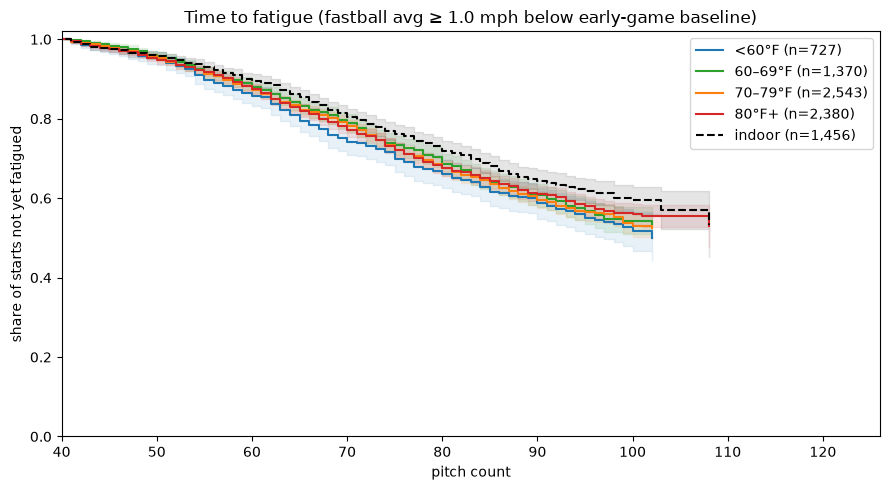

,group,starts,fatigued,median pitch count to fatigue
0,<60°F,727,292,NaN
1,60–69°F,1370,514,NaN
2,70–79°F,2543,967,NaN
3,80°F+,2380,868,NaN
4,indoor,1456,480,NaN


In [14]:
def kaplan_meier(time_, event):
    t = np.asarray(time_, float); e = np.asarray(event, int)
    uniq = np.sort(np.unique(t[e == 1]))
    s, xs, ys, var = 1.0, [0.0], [1.0], 0.0
    lo, hi = [1.0], [1.0]
    for u in uniq:
        n = (t >= u).sum(); d = ((t == u) & (e == 1)).sum()
        if n == 0:
            continue
        s *= 1 - d / n
        var += d / (n * (n - d)) if n > d else 0
        se = s * np.sqrt(var)
        xs.append(u); ys.append(s); lo.append(max(s - 1.96 * se, 0)); hi.append(min(s + 1.96 * se, 1))
    return np.array(xs), np.array(ys), np.array(lo), np.array(hi)

def median_survival(xs, ys):
    below = np.flatnonzero(ys <= 0.5)
    return xs[below[0]] if len(below) else np.nan

fig, ax = plt.subplots(figsize=(9, 5))
rows = []
groups = list(out.groupby("temp_bin", observed=True)) + [("indoor", df[df["indoor"]])]
colors = ["tab:blue", "tab:green", "tab:orange", "tab:red", "black"]
for (lab, g), c in zip(groups, colors):
    xs, ys, lo, hi = kaplan_meier(g["time"], g["event"])
    ax.step(xs, ys, where="post", color=c, label=f"{lab} (n={len(g):,})", ls="--" if lab == "indoor" else "-")
    ax.fill_between(xs, lo, hi, step="post", color=c, alpha=0.1)
    rows.append({"group": lab, "starts": len(g), "fatigued": g["event"].sum(),
                 "median pitch count to fatigue": median_survival(xs, ys)})
ax.set_xlim(BASE_HI, out["time"].max()); ax.set_ylim(0, 1.02)
ax.set_xlabel("pitch count"); ax.set_ylabel("share of starts not yet fatigued")
ax.set_title(f"Time to fatigue (fastball avg ≥ {DROP} mph below early-game baseline)")
ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

## 4d. Cox model: temperature effect, comparing each pitcher with himself

A Cox proportional-hazards model estimates how temperature changes the **rate** of hitting the fatigue point at any given pitch count. **Stratifying by pitcher** means every pitcher gets his own baseline fatigue pattern; temperature is estimated only from how the *same* pitcher does on hot vs. cool days. That removes differences between pitchers (and between teams that play in hot or cold cities).

Other factors included: month (season-long wear, which also correlates with temperature), day vs. night, days of rest, and early-game velocity.

**Hazard ratio (HR) per +10°F:** above 1 = fatigues sooner when hotter; below 1 = later; 1 = no effect. The 95% interval shows the uncertainty.

In [15]:
from statsmodels.duration.hazard_regression import PHReg

def cox(data, label):
    d = data.dropna(subset=["temp_f", "rest", "day_night"]).copy()
    X = pd.DataFrame({"temp_per_10F": d["temp_f"] / 10,
                      "baseline_velo": d["baseline_velo"] - d["baseline_velo"].mean(),
                      "month": d["month"] - d["month"].mean(),
                      "night": (d["day_night"] == "night").astype(float)})
    X = X.join(pd.get_dummies(d["rest"], prefix="rest", drop_first=True, dtype=float))
    res = PHReg(d["time"].to_numpy(float), X.to_numpy(float),
                status=d["event"].to_numpy(int), strata=d["pitcher"].to_numpy(),
                ties="efron").fit()
    ci = np.asarray(res.conf_int())
    tab = pd.DataFrame({"HR": np.exp(res.params), "95% low": np.exp(ci[:, 0]),
                        "95% high": np.exp(ci[:, 1]), "p": res.pvalues}, index=X.columns)
    print(f"{label}: {len(d):,} starts, {d['event'].sum():,} fatigue events, "
          f"{d['pitcher'].nunique():,} pitchers")
    display(tab.round(3))
    return tab

cox_outdoor = cox(out, "Outdoor starts")

Outdoor starts: 6,732 starts, 2,524 fatigue events, 335 pitchers


/var/folders/dz/mpq61s9s6lz4ymrnx6xjrx9m0000gn/T/ipykernel_42766/2995275954.py:15: RuntimeWarning: overflow encountered in exp
  "95% high": np.exp(ci[:, 1]), "p": res.pvalues}, index=X.columns)


,HR,95% low,95% high,p
temp_per_10F,9.280000e-01,0.888,0.971,0.001
baseline_velo,1.832000e+00,1.736,1.933,0.000
month,9.410000e-01,0.915,0.968,0.000
night,1.109000e+00,1.017,1.209,0.019
rest_5,2.279530e+12,0.000,inf,1.000
rest_6,2.604509e+12,0.000,inf,1.000
rest_7+,3.022047e+12,0.000,inf,1.000


Cox 模型(Cox 比例风险模型,Cox proportional hazards model)

$$h(t \mid X) = h_0(t) \times e^{\beta_1 X_1 + \beta_2 X_2 + \cdots}$$

$h_0(t)$:基准风险.   
$e^{\beta X}$:各个因素(气温、休息天数、日场/夜场)把风险整体放大或缩小多少倍。     
Hazard Ratio, HR = $e^{\beta X}$

HR>1: which means event happens earlier
HR=1: NO influence
HR<1: later

### Robustness checks
A real effect should hold up when the fatigue definition changes. This reruns the outdoor Cox model with a smaller and a larger velocity drop, and reports only the temperature hazard ratio.

In [16]:
checks = []
for drop in [0.75, 1.0, 1.5]:
    DROP = drop
    s2 = (st.groupby(["game_pk", "pitcher", "game_date"])
            .apply(fatigue_point, include_groups=False).dropna().reset_index())
    s2["event"] = s2["event"].astype(int)
    d2 = s2.merge(df[["game_pk", "pitcher", "temp_f", "indoor", "day_night", "month", "rest"]],
                  on=["game_pk", "pitcher"])
    tab = cox(d2[~d2["indoor"]], f"DROP = {drop} mph")
    checks.append({"DROP (mph)": drop, **tab.loc["temp_per_10F", ["HR", "95% low", "95% high", "p"]].to_dict()})
DROP = 1.0
display(pd.DataFrame(checks).round(3))

DROP = 0.75 mph: 6,732 starts, 3,498 fatigue events, 335 pitchers


/Users/jinzhixu/spark-env/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/var/folders/dz/mpq61s9s6lz4ymrnx6xjrx9m0000gn/T/ipykernel_42766/2995275954.py:15: RuntimeWarning: overflow encountered in exp
  "95% high": np.exp(ci[:, 1]), "p": res.pvalues}, index=X.columns)


,HR,95% low,95% high,p
temp_per_10F,9.290000e-01,0.894,0.965,0.000
baseline_velo,1.682000e+00,1.607,1.761,0.000
month,9.650000e-01,0.942,0.988,0.003
night,1.143000e+00,1.062,1.230,0.000
rest_5,1.121018e+07,0.000,inf,0.998
rest_6,1.203860e+07,0.000,inf,0.998
rest_7+,1.334953e+07,0.000,inf,0.998


DROP = 1.0 mph: 6,732 starts, 2,524 fatigue events, 335 pitchers


/var/folders/dz/mpq61s9s6lz4ymrnx6xjrx9m0000gn/T/ipykernel_42766/2995275954.py:15: RuntimeWarning: overflow encountered in exp
  "95% high": np.exp(ci[:, 1]), "p": res.pvalues}, index=X.columns)


,HR,95% low,95% high,p
temp_per_10F,9.280000e-01,0.888,0.971,0.001
baseline_velo,1.832000e+00,1.736,1.933,0.000
month,9.410000e-01,0.915,0.968,0.000
night,1.109000e+00,1.017,1.209,0.019
rest_5,1.808737e+12,0.000,inf,1.000
rest_6,2.066599e+12,0.000,inf,1.000
rest_7+,2.397902e+12,0.000,inf,1.000


DROP = 1.5 mph: 6,732 starts, 1,046 fatigue events, 335 pitchers


/Users/jinzhixu/spark-env/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/var/folders/dz/mpq61s9s6lz4ymrnx6xjrx9m0000gn/T/ipykernel_42766/2995275954.py:15: RuntimeWarning: overflow encountered in exp
  "95% high": np.exp(ci[:, 1]), "p": res.pvalues}, index=X.columns)


,HR,95% low,95% high,p
temp_per_10F,0.909,0.849,0.974,0.007
baseline_velo,2.103,1.934,2.287,0.000
month,0.907,0.868,0.947,0.000
night,1.045,0.913,1.196,0.522
rest_5,27145.325,0.000,inf,0.993
rest_6,33475.711,0.000,inf,0.992
rest_7+,37947.044,0.000,inf,0.992


,DROP (mph),HR,95% low,95% high,p
0,0.75,0.929,0.894,0.965,0.000
1,1.00,0.928,0.888,0.971,0.001
2,1.50,0.909,0.849,0.974,0.007


## How to read the results, and the limits

- **4a** tells you whether heat changes how hard pitchers throw at all. **4c/4d** tell you whether it changes *when* they tire. These are different questions.
- A hazard ratio near 1 with an interval spanning 1 means no detectable temperature effect on fatigue timing, which is a legitimate finding.

**Limitations to state in any write-up**
- **Managers decide when starts end, often because the pitcher looks tired.** That makes censoring related to fatigue itself, which survival analysis assumes it isn't. Results describe "fatigue among pitchers still in the game."
- **Temperature is at first pitch only,** and the API has no humidity. Heat stress depends on both; a next step is adding hourly temperature and dew point from a historical weather service using each ballpark's location.
- **Fatigue is measured by fastball velocity only.** Command, spin rate or release point could tire on a different schedule.
- **Temperature goes with other things:** month, day games, and certain ballparks (stratifying by pitcher and adjusting for month and day/night reduces this, but doesn't remove it).